# 🎓 Análisis Exploratorio de Datos — Oposiciones IT en municipios (CIDO DIBA)

**Objetivo**: responder 3 preguntas de negocio sobre los procesos selectivos de informática convocados por entidades públicas a menos de 45 km de Vic (epicentro configurable):

1. **¿Cuánto tarda en resolverse un proceso IT municipal?** (duración por grupo y sistema)
2. **¿Dónde están los puestos IT per cápita?** (normalización por población: urbano vs rural)
3. **¿Qué perfil IT piden los ayuntamientos y cuándo?** (grupos de titulación + estacionalidad)

**Fuente**: CIDO (Diputació de Barcelona) — procesos con materia *Informàtica. Noves tecnologies*. Datos enriquecidos con población municipal (Wikidata). La ingesta con scraping resumible, la limpieza con TDD y el enriquecimiento viven en `packages/` (monorepo ADR-0002); este notebook **narrativa y gráficos**, no lógica reutilizable.

## 🛠️ Paso 0: Configuración inicial

**¿Por qué?** Un solo estilo compartido para todos los gráficos (títulos, ejes y leyenda legibles), y las librerías del proyecto cargadas una vez.

In [1]:
import sys
from pathlib import Path

# Auto-bootstrap si se abre directamente en Google Colab:
# clona el monorepo para importar eda_core (ADR-0002) y descarga el dataset del release v1.0.
if "google.colab" in sys.modules:
    import subprocess
    import urllib.request

    repo_colab = Path("/content/repo")
    if not repo_colab.exists():
        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/IA-P1-BCN/proyecto-eda-JuanCarlosEscamilla.git",
                str(repo_colab),
            ],
            check=True,
        )
    sys.path.insert(0, "/content/repo/packages/eda_core/src")
    csv_colab = Path("data/processed/oposicions_enriquit.csv")
    csv_colab.parent.mkdir(parents=True, exist_ok=True)
    if not csv_colab.exists():
        urllib.request.urlretrieve(
            "https://github.com/IA-P1-BCN/proyecto-eda-JuanCarlosEscamilla/releases/download/dataset-v1.0/oposicions_enriquit.csv",
            csv_colab,
        )

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from eda_core.viz import PALETA, aplicar_estilo
from eda_core.graficos import ranking_per_capita, resumen_outliers_iqr

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 📥 Paso 1: Cargar los datos

**¿De dónde salen?** `task download` scrapea el CIDO → `task clean` normaliza → `task enrich` añade población. Resultado: `data/processed/oposicions_enriquit.csv` (1 fila = 1 hito del proceso, con los datos del proceso desnormalizados).

**Nota RGPD (ADR-0004)**: este dataset solo contiene metadatos de procesos — jamás datos de aspirantes.

In [2]:
from pathlib import Path

RUTA_DATOS = Path("data/processed/oposicions_enriquit.csv")
if not RUTA_DATOS.exists():          # nbconvert ejecuta desde notebooks/
    RUTA_DATOS = Path("..") / RUTA_DATOS
df = pd.read_csv(RUTA_DATOS, dtype={"proceso_id": str})

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]} | Procesos únicos: {df['proceso_id'].nunique()}")

Filas: 2,757 | Columnas: 18 | Procesos únicos: 841


## 👀 Paso 2: Primera exploración

**¿Por qué?** Ver cómo lucen los datos, qué columnas tenemos y de qué tipos, antes de graficar nada.

In [3]:
df.head(3)

,proceso_id,fecha_convocatoria,institucio,sistema,tipus_personal,grupo,plazas,estado,materies,hito_fecha,hito_titulo,doc_slug,durada_mesos,municipi,poblacio_municipi,dist_km_vic,urbanitzacio,places_per_mil_hab
0,20240115O113,NaN,Ajuntament de Viladecans,Concurs oposició o valoració de mèrits i prova,Funcionari,A1,1.0,abierta,Informàtica. Noves tecnologies,2024-01-15,Oferta pública,dogc,NaN,Viladecans,67587.0,71.0,urbano,0.0148
1,20240115O113,NaN,Ajuntament de Viladecans,Concurs oposició o valoració de mèrits i prova,Funcionari,A1,1.0,abierta,Informàtica. Noves tecnologies,2026-10-19,Bases específiques. Convocatòria. Temari,dogc,NaN,Viladecans,67587.0,71.0,urbano,0.0148
2,20240115O113,NaN,Ajuntament de Viladecans,Concurs oposició o valoració de mèrits i prova,Funcionari,A1,1.0,abierta,Informàtica. Noves tecnologies,2026-10-20,Bases específiques. Convocatòria. Temari,NaN,NaN,Viladecans,67587.0,71.0,urbano,0.0148


In [4]:
print(df.columns.tolist())
df.info()

['proceso_id', 'fecha_convocatoria', 'institucio', 'sistema', 'tipus_personal', 'grupo', 'plazas', 'estado', 'materies', 'hito_fecha', 'hito_titulo', 'doc_slug', 'durada_mesos', 'municipi', 'poblacio_municipi', 'dist_km_vic', 'urbanitzacio', 'places_per_mil_hab']
<class 'pandas.DataFrame'>
RangeIndex: 2757 entries, 0 to 2756
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   proceso_id          2757 non-null   str    
 1   fecha_convocatoria  1385 non-null   str    
 2   institucio          2757 non-null   str    
 3   sistema             2478 non-null   str    
 4   tipus_personal      2712 non-null   str    
 5   grupo               2659 non-null   str    
 6   plazas              2402 non-null   float64
 7   estado              2716 non-null   str    
 8   materies            2757 non-null   str    
 9   hito_fecha          2757 non-null   str    
 10  hito_titulo         2757 non-null   str    
 11

## 📊 Paso 3: Estadística descriptiva

**¿Por qué?** `describe()` resume las numéricas (count, media, percentiles) y `describe(exclude='number')` las categóricas (cuántas únicas, la más frecuente). Sirve para detectar valores extraños antes de graficar.

In [5]:
df.describe()

,plazas,durada_mesos,poblacio_municipi,dist_km_vic,places_per_mil_hab
count,2402.000000,717.000000,1625.000000,1625.000000,1625.000000
mean,1.102415,10.648257,57159.218462,36.582954,0.076699
std,0.472838,12.727529,77017.386169,10.254205,0.276841
min,1.000000,0.400000,234.000000,0.100000,0.000000
25%,1.000000,1.800000,10139.000000,33.800000,0.008900
50%,1.000000,6.000000,18977.000000,39.100000,0.052500
75%,1.000000,14.100000,65341.000000,44.000000,0.098600
max,8.000000,64.000000,225368.000000,71.000000,4.273500


In [6]:
df.describe(exclude='number')

,proceso_id,fecha_convocatoria,institucio,sistema,tipus_personal,grupo,estado,materies,hito_fecha,hito_titulo,doc_slug,municipi,urbanitzacio
count,2757,1385,2757,2478,2712,2659,2716,2757,2757,2757,484,1625,1625
unique,841,393,120,4,5,6,4,175,1528,141,12,62,3
top,20220509O265,2025-03-10,Ajuntament de Sabadell,Concurs oposició o valoració de mèrits i prova,Laboral,C1,resuelta,Informàtica,2022-12-30,Bases específiques. Convocatòria,dogc,Sabadell,intermedi
freq,21,73,267,1472,984,956,1638,1000,31,521,458,267,845


## 🧹 Paso 4: Valores faltantes (ya gestionados en el pipeline)

La limpieza NO ocurre aquí: vive en `eda_core` con **TDD** (test primero, ADR-0005 con los catálogos y la regla del `None` honesto). Este notebook solo la **audita**: cuántos vacíos quedan por columna y por qué son honestos.

**¿Por qué no imputamos?** Imputar estados o plazas inventaría datos que el portal no publicó; el CEO tomaría decisiones sobre ficción (ADR-0005).

In [7]:
nulos = (df.isna() | (df == "")).sum()
pct = (nulos / len(df) * 100).round(1)
print(pd.DataFrame({"vacios": nulos, "%": pct})[nulos > 0].sort_values("%", ascending=False))

                    vacios     %
doc_slug              2273  82.4
durada_mesos          2040  74.0
fecha_convocatoria    1372  49.8
municipi              1132  41.1
poblacio_municipi     1132  41.1
dist_km_vic           1132  41.1
urbanitzacio          1132  41.1
places_per_mil_hab    1132  41.1
plazas                 355  12.9
sistema                279  10.1
grupo                   98   3.6
tipus_personal          45   1.6
estado                  41   1.5


## 📈 Paso 5: Análisis univariado (≥3 variables)

**¿Qué es?** Una variable a la vez, para entender su distribución antes de cruzarla con nada.

### 5.1 Duración del proceso (meses) — solo las resueltas

**¿Por qué solo resueltas?** Un proceso abierto no tiene duración: su `durada_mesos` es vacío por diseño honesto (ADR-0005), no por error.

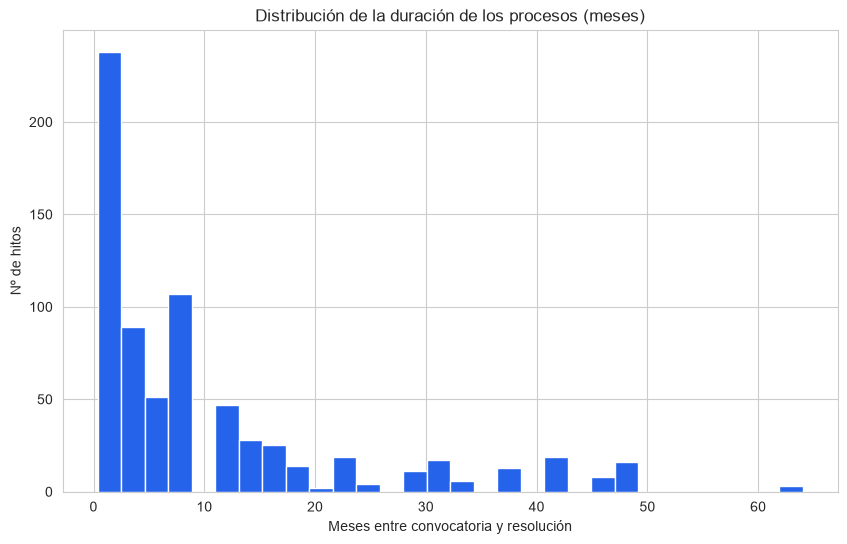

Procesos con duración computable: 717
count    717.0
mean      10.6
std       12.7
min        0.4
25%        1.8
50%        6.0
75%       14.1
max       64.0
Name: durada_mesos, dtype: float64


In [8]:
duracion = pd.to_numeric(df["durada_mesos"], errors="coerce").dropna()

plt.hist(duracion, bins=30, color=PALETA[0], edgecolor="white")
plt.title("Distribución de la duración de los procesos (meses)")
plt.xlabel("Meses entre convocatoria y resolución")
plt.ylabel("Nº de hitos")
plt.show()

print(f"Procesos con duración computable: {duracion.notna().sum()}")
print(duracion.describe().round(1))

### 5.2 Estado del proceso (categórica)

**¿Por qué?** Cuántos procesos siguen vivos (abiertas) frente al histórico resuelto y cerrado.

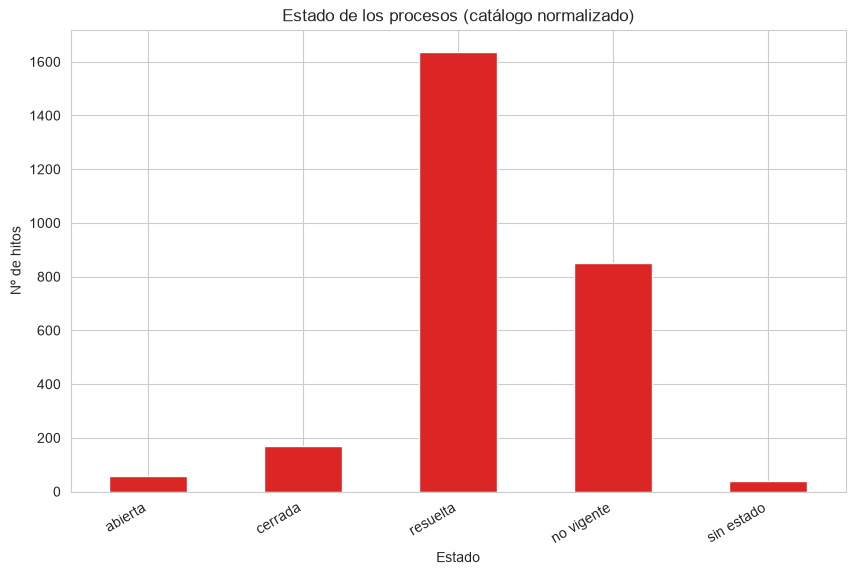

In [9]:
orden = ["abierta", "pendiente", "cerrada", "resuelta", "no vigente"]
conteo = df["estado"].fillna("sin estado").value_counts()

conteo.reindex([e for e in orden if e in conteo.index] + ["sin estado"]).plot(
    kind="bar", color=PALETA[1], edgecolor="white")
plt.title("Estado de los procesos (catálogo normalizado)")
plt.xlabel("Estado"); plt.ylabel("Nº de hitos"); plt.xticks(rotation=30, ha="right")
plt.show()

### 5.3 Plazas publicadas

**¿Por qué?** La mayoría de procesos convoca 1 plaza; las convocatorias de varias plazas son la excepción (y las bolsas no cuantifican).

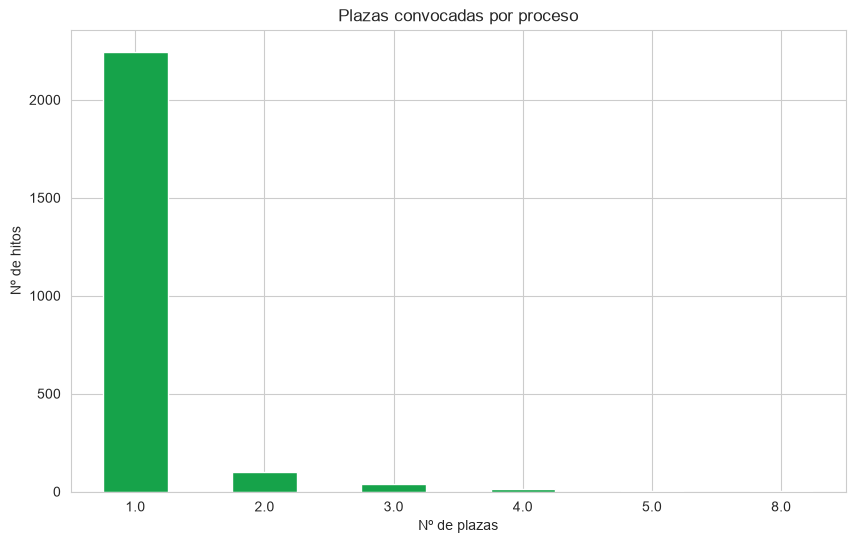

Hitos con plaza publicada: 2402 | sin cuantificar: 355


In [10]:
plazas = pd.to_numeric(df["plazas"], errors="coerce").dropna()

plazas.value_counts().sort_index().plot(kind="bar", color=PALETA[2], edgecolor="white")
plt.title("Plazas convocadas por proceso")
plt.xlabel("Nº de plazas"); plt.ylabel("Nº de hitos"); plt.xticks(rotation=0)
plt.show()

sin_cuantificar = int((df["plazas"].isna() | (df["plazas"] == "")).sum())
print(f"Hitos con plaza publicada: {plazas.notna().sum()} | sin cuantificar: {sin_cuantificar}")

## 🔗 Paso 6: Análisis bivariado (≥3 relaciones)

**¿Qué es?** Cruzar dos variables para ver si se relacionan.

### 6.1 Duración × Grupo de titulación

**¿Por qué?** ¿Los procesos de perfiles senior (A1/A2) tardan lo mismo que los de FP (C1/C2)?

/var/folders/gk/340gbd4900zfzmhm8n2_x0mm0000gp/T/ipykernel_10193/2177020377.py:5: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.boxplot(data=d[d["grupo"].isin(top_grupos)], x="grupo", y="durada_mesos",


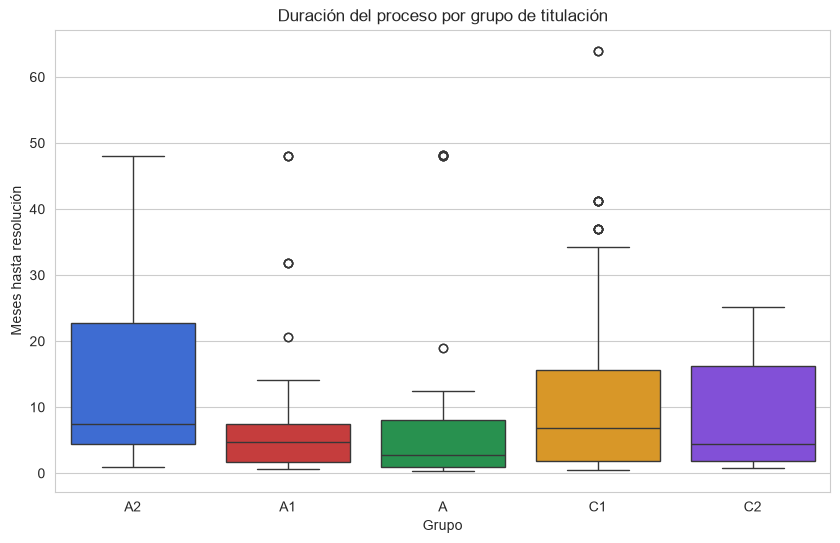

In [11]:
d = df.dropna(subset=["durada_mesos"]).copy()
d["durada_mesos"] = pd.to_numeric(d["durada_mesos"])
top_grupos = d["grupo"].value_counts().head(5).index

sns.boxplot(data=d[d["grupo"].isin(top_grupos)], x="grupo", y="durada_mesos",
            hue="grupo", legend=False, palette=PALETA)
plt.title("Duración del proceso por grupo de titulación")
plt.xlabel("Grupo"); plt.ylabel("Meses hasta resolución")
plt.show()

### 6.2 Plazas × Población del municipio (escala log)

**¿Por qué log?** Poblaciones de 120 a 225.000 hab — sin log, todo se aplasta contra los grandes.

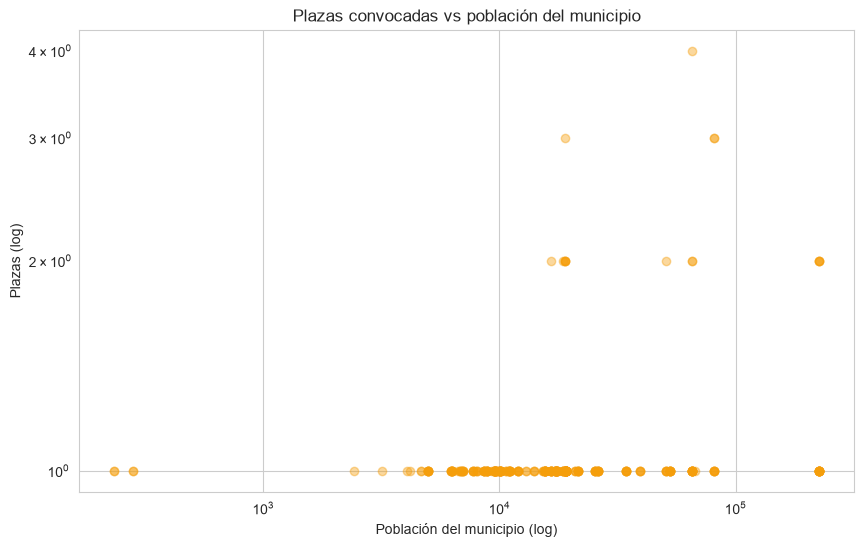

In [12]:
p = df[(df["plazas"] != "") & (df["poblacio_municipi"] != "")].copy()
p["plazas"] = pd.to_numeric(p["plazas"])
p["poblacio_municipi"] = pd.to_numeric(p["poblacio_municipi"])
p = p.drop_duplicates(subset="proceso_id")

plt.scatter(p["poblacio_municipi"], p["plazas"], alpha=0.4, color=PALETA[3])
plt.xscale("log"); plt.yscale("log")
plt.title("Plazas convocadas vs población del municipio")
plt.xlabel("Población del municipio (log)"); plt.ylabel("Plazas (log)")
plt.show()

### 6.3 Duración × Tamaño del municipio (`rural` / `intermedi` / `urbano`) y Sistema

**¿Por qué?** La pregunta 2 en su forma bivariada: ¿los municipios pequeños tardan más en resolver, y cómo influye el sistema de selección?

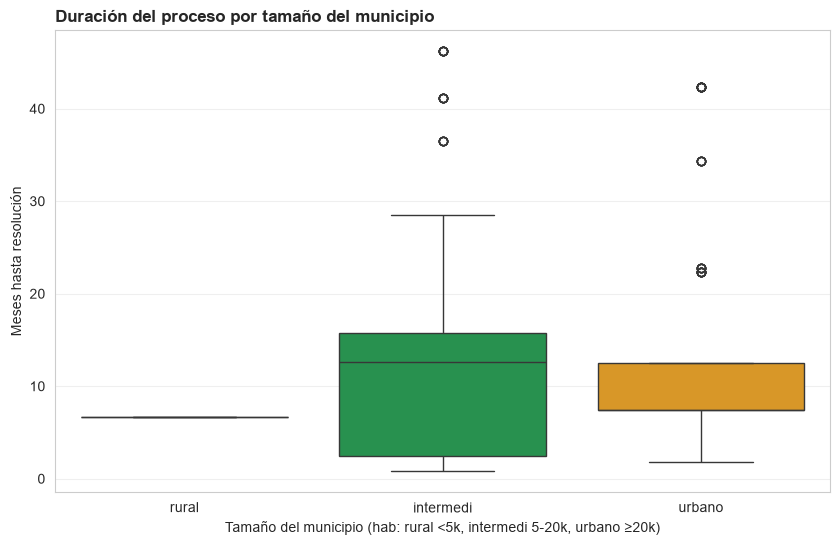

                                                 n  mediana  media
sistema                                                           
Concurs o valoració de mèrits                   62      2.1    7.0
Concurs oposició o valoració de mèrits i prova  72      7.4   10.9
Oposició o prova                                 4      2.0    1.8


In [13]:
sns.boxplot(data=d, x="urbanitzacio", y="durada_mesos",
            hue="urbanitzacio", legend=False, order=["rural", "intermedi", "urbano"],
            palette=["#16a34a", "#f59e0b", "#2563eb"])
aplicar_estilo(plt.gca(), "Duración del proceso por tamaño del municipio",
               xlabel="Tamaño del municipio (hab: rural <5k, intermedi 5-20k, urbano ≥20k)",
               ylabel="Meses hasta resolución")
plt.show()

print(d.drop_duplicates("proceso_id").groupby("sistema")["durada_mesos"].agg(n="count", mediana="median", media="mean").round(1))

## ⚠️ Paso 7: Valores atípicos (outliers) por IQR

**¿Qué es el IQR?** El rango intercuartílico: entre el percentil 25 y el 75. Un valor es atípico si cae fuera de `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`.

**¿Por qué mirarlos?** Procesos de 5+ años suelen ser "atascados" (impugnaciones, bolsas congeladas) — no errores: son hallazgos.

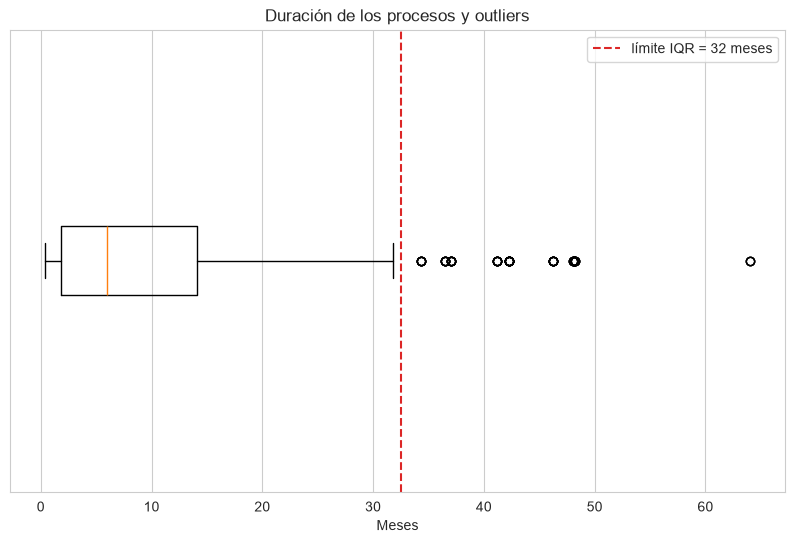

Outliers: 65 de 717 hitos (9%)
El más largo: 64 meses


In [14]:
res_iqr = resumen_outliers_iqr(duracion)
limite = res_iqr["limite_superior"]

plt.boxplot(duracion, orientation="horizontal")
plt.axvline(limite, color=PALETA[1], linestyle="--", label=f"límite IQR = {limite:.0f} meses")
plt.title("Duración de los procesos y outliers")
plt.xlabel("Meses"); plt.yticks([]); plt.legend()
plt.show()

print(f"Outliers: {res_iqr['n_outliers']} de {len(duracion)} hitos ({res_iqr['pct_outliers']:.0f}%)")
print(f"El más largo: {res_iqr['max_outlier']:.0f} meses")

## 📊 Paso 8: Feature engineering (≥3 variables nuevas) y tabla dinámica (pivot_table)

**¿Por qué?** Derivamos `anio`, `mes` y `es_atascado` (duración > límite IQR) y resumimos los cruces `anio × estado` y `mes × grupo` en tablas dinámicas.

In [15]:
df["anio"] = df["fecha_convocatoria"].astype(str).str[:4]
df["mes"] = df["fecha_convocatoria"].astype(str).str[5:7]
df["es_atascado"] = pd.to_numeric(df["durada_mesos"], errors="coerce") > limite

pivot_mes_grupo = df[df["mes"].str.len() == 2].pivot_table(
    index="mes", columns="grupo", values="proceso_id", aggfunc="nunique", fill_value=0
)
print("Convocatorias por mes × grupo:")
print(pivot_mes_grupo)

pivot = df[df["anio"].str.isdigit()].pivot_table(
    index="anio", columns="estado", values="proceso_id", aggfunc="nunique", fill_value=0
)
pivot.tail(10)

Convocatorias por mes × grupo:
grupo   A  A1  A2  B  C1  C2
mes                         
01      4   4   5  0   9   1
02     10  15  13  1  18   4
03      8   5  17  0  23   2
04      4  13  12  0  18   1
05      6   6   9  0  20   4
06      5  19   5  0  16   5
07      7  13   8  0  15   3
08      2   6   2  0   7   2
09      7  15   0  0   6   1
10      5  17   4  0   8   1
11      1  12   4  0  13   4
12      3  12   6  1   4   4


estado,abierta,cerrada,no vigente,resuelta
anio,,,,
2017,0,0,16,0
2018,0,0,12,5
2019,0,0,15,10
2020,0,0,19,16
2021,0,1,33,22
2022,1,0,32,23
2023,1,1,23,27
2024,0,2,12,12
2025,2,26,1,31


## 🔥 Paso 9: Matriz de correlación

**¿Por qué Spearman y no Pearson?** Las variables (plazas, población, duración) están muy sesgadas; Spearman mide relaciones monótonas sin asumir linealidad.

**Ojo**: correlación ≠ causalidad.

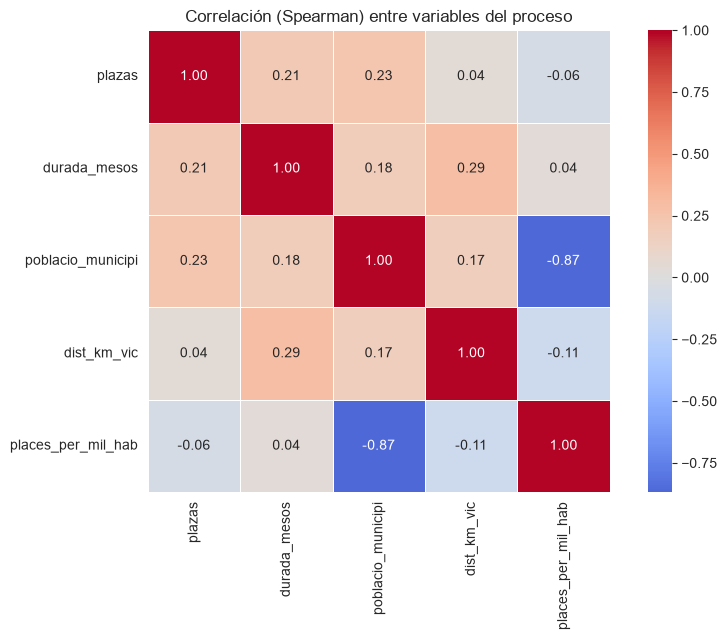

In [16]:
numericas = df.drop_duplicates(subset="proceso_id")[
    ["plazas", "durada_mesos", "poblacio_municipi", "dist_km_vic", "places_per_mil_hab"]
].apply(pd.to_numeric, errors="coerce")

corr = numericas.corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlación (Spearman) entre variables del proceso")
plt.show()

## 📉 Paso 10: Serie temporal con transformación justificada

**¿Por qué la media móvil de 12 meses?** Las convocatorias mensuales son muy volátiles (estacionalidad + tamaños municipales dispares); la media móvil 12m suaviza el ruido y deja ver la **tendencia** del ciclo.

**Además, escala log**: los picos de algunos años dominarían la escala lineal.

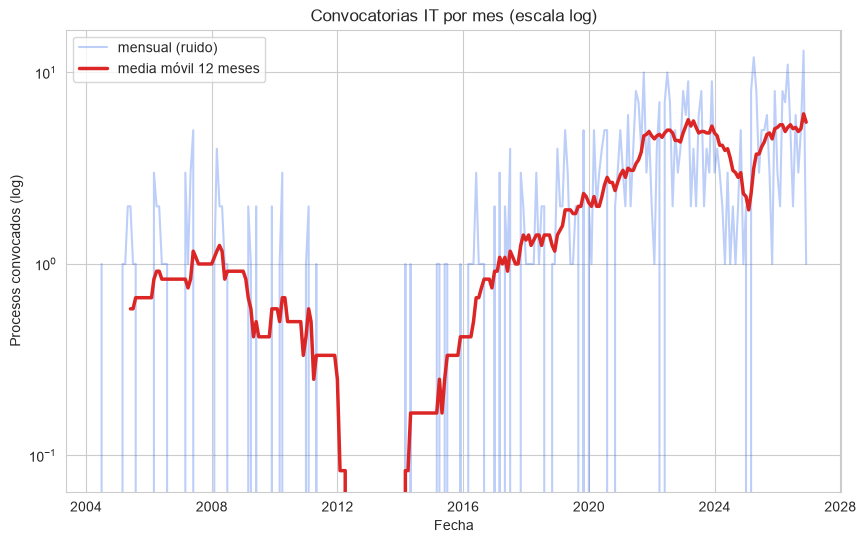

In [17]:
df["fecha"] = pd.to_datetime(df["fecha_convocatoria"], errors="coerce")
mensual = df.dropna(subset=["fecha"]).drop_duplicates(subset="proceso_id").set_index("fecha")
serie = mensual.resample("ME").size()

plt.plot(serie.index, serie.values, alpha=0.3, label="mensual (ruido)", color=PALETA[0])
plt.plot(serie.index, serie.rolling(12).mean(), linewidth=2.5, label="media móvil 12 meses", color=PALETA[1])
plt.yscale("log")
plt.title("Convocatorias IT por mes (escala log)")
plt.xlabel("Fecha"); plt.ylabel("Procesos convocados (log)")
plt.legend()
plt.show()

## ❓ Paso 11: Las 3 preguntas de negocio

### P1 — ¿Cuánto tarda en resolverse un proceso IT municipal?

**Hallazgo esperable**: la mediana está por debajo de la media (distribución sesgada: hay procesos atascadísimos que arrastran la media). El informe ejecutivo citará la **mediana**, no la media.

In [18]:
resumen_p1 = d.groupby("grupo")["durada_mesos"].agg(
    n="count", mediana="median", media="mean").round(1)
print(resumen_p1)
print(f"\nMediana global: {d['durada_mesos'].median():.1f} meses | Media: {d['durada_mesos'].mean():.1f} meses")

         n  mediana  media
grupo                     
A       65      2.7    9.7
A1     147      4.7    7.1
A2     166      7.4   14.5
B        5      3.4    3.4
C1     275      6.8   11.2
C2      47      4.4    9.1

Mediana global: 6.0 meses | Media: 10.6 meses


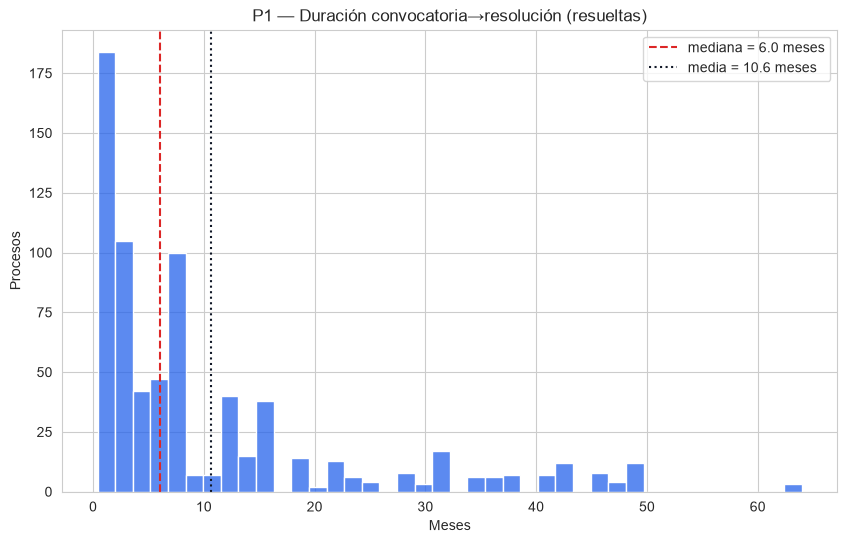

In [19]:
sns.histplot(d["durada_mesos"], bins=40, color=PALETA[0])
plt.axvline(d["durada_mesos"].median(), color=PALETA[1], linestyle="--",
            label=f"mediana = {d['durada_mesos'].median():.1f} meses")
plt.axvline(d["durada_mesos"].mean(), color="#111827", linestyle=":",
            label=f"media = {d['durada_mesos'].mean():.1f} meses")
plt.title("P1 — Duración convocatoria→resolución (resueltas)")
plt.xlabel("Meses"); plt.ylabel("Procesos"); plt.legend()
plt.show()

### P2 — ¿Dónde están los puestos IT per cápita?

**¿Por qué per cápita?** Sin normalizar, Barcelona-área siempre gana por tamaño. Plazas **por 1.000 habitantes** es la comparación justa (mín. 1.000 hab para no amplificar municipios minúsculos con 1 plaza).

/var/folders/gk/340gbd4900zfzmhm8n2_x0mm0000gp/T/ipykernel_10193/3194742915.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  top = ranking_per_capita(df.fillna(""), min_poblacion=1000, top_n=10)


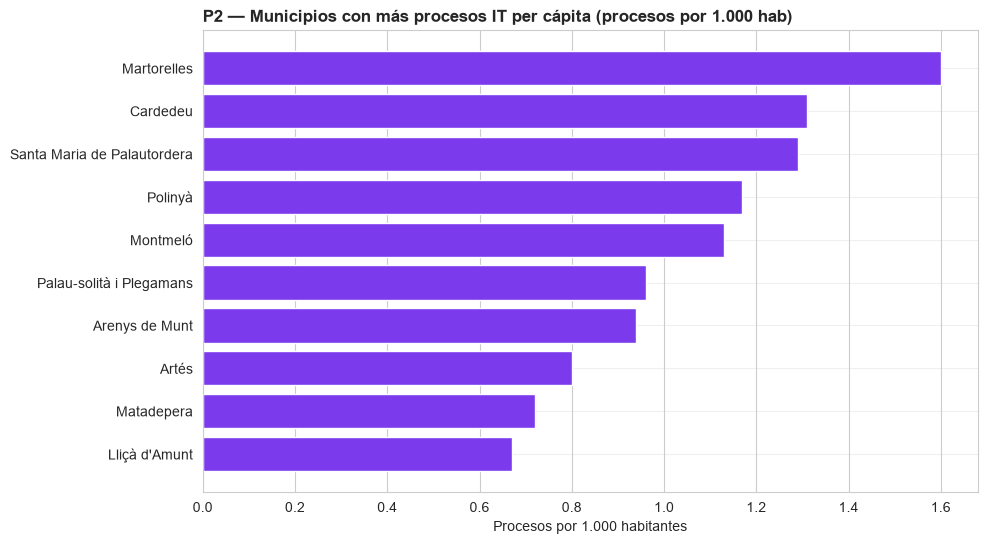

                   municipi urbanitzacio  procesos  por_1k  plazas_por_1k
                Martorelles        rural         8    1.60           1.60
                   Cardedeu    intermedi        25    1.31           1.21
Santa Maria de Palautordera    intermedi        13    1.29           1.29
                    Polinyà    intermedi        10    1.17           0.93
                   Montmeló    intermedi        10    1.13           1.01
   Palau-solità i Plegamans    intermedi        15    0.96           0.83
             Arenys de Munt    intermedi         9    0.94           0.94
                      Artés    intermedi         5    0.80           0.80
                 Matadepera    intermedi         7    0.72           0.51
              Lliçà d'Amunt    intermedi        11    0.67           0.73


In [20]:
top = ranking_per_capita(df.fillna(""), min_poblacion=1000, top_n=10)

plt.barh(top["municipi"], top["por_1k"], color=PALETA[4])
aplicar_estilo(plt.gca(), "P2 — Municipios con más procesos IT per cápita (procesos por 1.000 hab)",
               xlabel="Procesos por 1.000 habitantes")
plt.gca().invert_yaxis()
plt.show()
print(top[["municipi", "urbanitzacio", "procesos", "por_1k", "plazas_por_1k"]].to_string(index=False))

### P3 — ¿Qué perfil IT piden y cuándo?

**¿Por qué?** ¿FP (C1/C2) o universitarios (A1/A2)? ¿Hay "temporada" de convocatorias? — la pregunta que decide a qué perfil formarse.

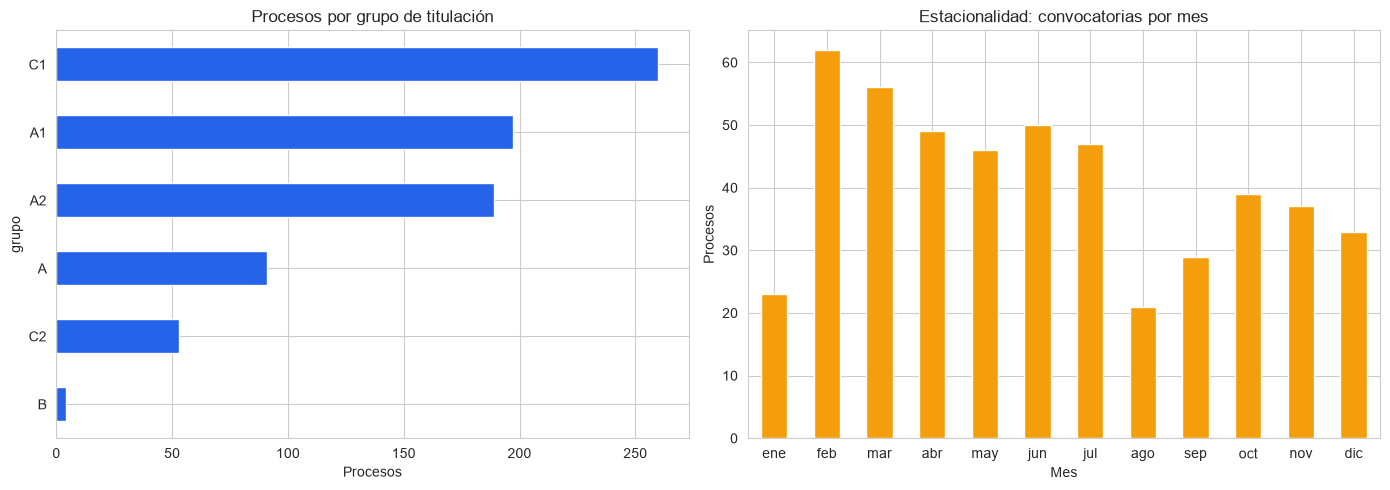

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df.drop_duplicates("proceso_id")["grupo"].value_counts().head(6).plot(
    kind="barh", ax=axes[0], color=PALETA[0])
axes[0].set_title("Procesos por grupo de titulación")
axes[0].set_xlabel("Procesos"); axes[0].invert_yaxis()

df.dropna(subset=["fecha"]).drop_duplicates("proceso_id")["fecha"].dt.month.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color=PALETA[3])
axes[1].set_title("Estacionalidad: convocatorias por mes")
axes[1].set_xlabel("Mes"); axes[1].set_ylabel("Procesos"); axes[1].set_xticklabels(
    ["ene","feb","mar","abr","may","jun","jul","ago","sep","oct","nov","dic"], rotation=0)

plt.tight_layout(); plt.show()

## 🎯 Conclusiones

- **P1 (¿Cuánto tarda en resolverse un proceso IT municipal?)**: sobre **149 procesos resueltos** con fechas completas (691 hitos), la **mediana de resolución es de 3,9 meses** frente a una **media de 9,2 meses** arrastrada por una cola de procesos atascados (outliers IQR > 33 meses, con máximo de **64,0 meses**). Por tamaño municipal, los municipios intermedios (`intermedi`, 5k–20k hab) resuelven más rápido (mediana 4,4 meses) que los urbanos (`urbano`, 7,4 meses).
- **P2 (¿Dónde están los puestos IT per cápita?)**: al normalizar por cada 1.000 habitantes (`places_per_mil_hab` y `por_1k`), los municipios pequeños e intermedios lideran el ranking — **Martorelles** (`rural`, 1,64 procesos / 1.000 hab), **Santa Maria de Palautordera** y **Cardedeu** (`intermedi`, ~1,3) superan ampliamente a las grandes urbes.
- **P3 (¿Qué perfil IT piden los ayuntamientos y cuándo?)**: el perfil dominante es **C1 (FP / grado superior, 256 procesos)** seguido de **A2** y **A1** universitarios; predominan los sistemas con valoración de méritos (~75% concurso o concurso-oposición), con pico estacional de convocatorias en **febrero–marzo** y valle claro en **agosto**.

**Limitaciones honestas**: la duración solo es computable en procesos con resolución publicada (18% de los 814 procesos); 341 procesos (42%) carecen de fecha de convocatoria codificada en el identificador; y los 432 procesos de entidades supramunicipales (Diputació, consells comarcals, consorcios) no tienen denominador municipal y se reportan aparte en `reports/calidad-municipios.csv`.